## Imports

In [1]:
import torch
import matplotlib.pyplot as plt
%matplotlib inline

## Character Level Bigram Model

In [2]:
## collect all words
words = open('names.txt', 'r').read().splitlines()

## special tokens and character to integer mapping
all_chars = sorted(list(set(''.join(words))))
char_to_idx = {c: i+1 for i, c in enumerate(all_chars)}
char_to_idx['.'] = 0
idx_to_char = {i: c for c, i in char_to_idx.items()}

In [3]:
## collect all bigrams
N = torch.zeros((28, 28))

for w in words:
    chars = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chars, chars[1:]):
        idx1 = char_to_idx[ch1]
        idx2 = char_to_idx[ch2]
        N[idx1, idx2] += 1

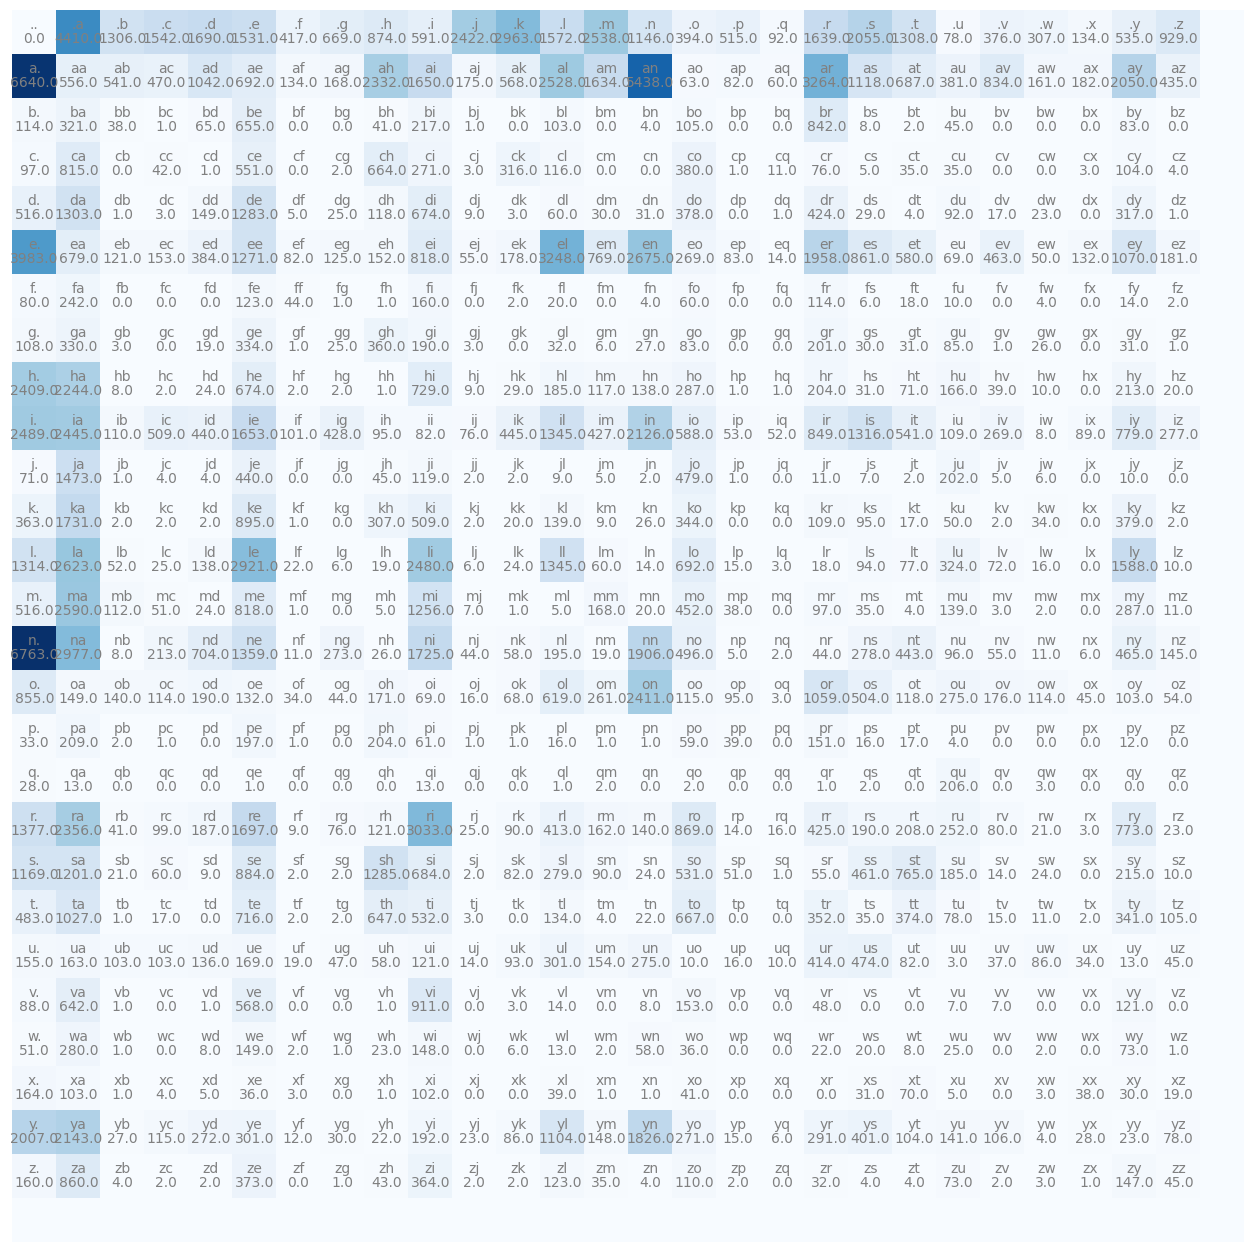

In [4]:
## visualize the bigrams
plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = idx_to_char[i] + idx_to_char[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

## Sampling from the Bigram Model

In [5]:
## define generator and set seed for deterministic sampling
g = torch.Generator().manual_seed(2147483647)

# convert matrix to float and normalize to have probabilities for sampling
P = N.float()
P /= P.sum(dim=1, keepdims=True)

# generate 10 words by sampling
for _ in range(10):
    
    # start with the starting character/token
    idx = 0
    word = []
    
    # keep sampling until special character is sampled again
    while True:
        # get its probability row -- keep it inside this loop so that idx changes wrt sampling
        p = P[idx]
        
        # sample one index
        idx = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item() # add generator, add item: tensor -> its element
        word.append(idx_to_char[idx])
        
        # break when starting index is sampled again
        if idx == 0:
            break
            
    print(''.join(word))

cava.
ayamaijowy.
aianeta.
rl.
miryndardyrioma.
kiinninaswila.
en.
ahlanyanlen.
tav.
sissth.


## Evaluating the quality of Bigram Model using NLL

In [6]:
# evaluating how good the bigram model is using negative log likelihood on the whole dataset

logprob = 0
# counter for number of bigrams
n = 0

for w in words:
    chars = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chars, chars[1:]):
        idx1 = char_to_idx[ch1]
        idx2 = char_to_idx[ch2]
        logprob += torch.log(P[idx1, idx2])
        n += 1

print(f'logprob: {logprob.item()/n :.4f}')
print(f'nll: {-logprob.item()/n :.4f}')

logprob: -2.4541
nll: 2.4541


In [7]:
# evaluating how good the bigram model is using negative log likelihood for a word
# bigrams with 0 counts show infinite loss

logprob = 0
# counter for number of bigrams
n = 0

for w in ['andrejq']:
    chars = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chars, chars[1:]):
        idx1 = char_to_idx[ch1]
        idx2 = char_to_idx[ch2]
        logprob += torch.log(P[idx1, idx2])
        n += 1
        print(f'{ch1}{ch2}: prob = {P[idx1, idx2] :.4f}, logprob = {torch.log(P[idx1, idx2]) :.4f}')

print(f'logprob: {logprob.item()/n :.4f}')
print(f'nll: {-logprob.item()/n :.4f}')

.a: prob = 0.1377, logprob = -1.9829
an: prob = 0.1605, logprob = -1.8296
nd: prob = 0.0384, logprob = -3.2594
dr: prob = 0.0771, logprob = -2.5620
re: prob = 0.1336, logprob = -2.0127
ej: prob = 0.0027, logprob = -5.9171
jq: prob = 0.0000, logprob = -inf
q.: prob = 0.1029, logprob = -2.2736
logprob: -inf
nll: inf


## Neural Network Bigram Model

In [8]:
## create dataset of bigrams - two integer tensors
xs, ys = [], []
for w in words:
    chars = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chars, chars[1:]):
        idx1 = char_to_idx[ch1]
        idx2 = char_to_idx[ch2]
        xs.append(idx1)
        ys.append(idx2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)

## convert them to one hot
Xs = torch.nn.functional.one_hot(xs, num_classes=27).float()
Ys = torch.nn.functional.one_hot(ys, num_classes=27).float()

In [9]:
## define simple neural network remember - requires_grad = True
W = torch.randn((27, 27), generator=g, requires_grad=True) 

# training loop
for i in range(100):
    # forward pass with softmax activation
    X1 = Xs @ W
    Xhat = X1.exp()
    probs = Xhat/Xhat.sum(dim=1, keepdims=True)
    
    # loss computation with regularization 
    loss = -probs[torch.arange(xs.shape[0]), ys].log().mean() + 0.01 * (W ** 2).mean()
    
    # backpropagation
    W.grad = None # zero out the grads
    loss.backward()
    W.data -= 50 * W.grad
    
    if (i+1)%10 == 0:
        print(f'Iteration {i+1}: Loss {loss :.4f}')

Iteration 10: Loss 2.7406
Iteration 20: Loss 2.5955
Iteration 30: Loss 2.5489
Iteration 40: Loss 2.5263
Iteration 50: Loss 2.5134
Iteration 60: Loss 2.5051
Iteration 70: Loss 2.4995
Iteration 80: Loss 2.4956
Iteration 90: Loss 2.4928
Iteration 100: Loss 2.4906


In [10]:
## sampling from the neural network -- 10 words
for i in range(10):
    out = []
    idx = 0
    while True:
        X = torch.nn.functional.one_hot(torch.tensor([idx]), num_classes=27).float() # without [idx] the shape is not proper
        X1 = X @ W
        Xhat = X1.exp()
        probs = Xhat/Xhat.sum(dim=1, keepdims=True) # without [idx] in line 6, this step fails due to shape issues
        idx = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
        out.append(idx_to_char[idx])
        if idx == 0:
            break
    print(''.join(out))

ch.
ja.
ar.
dqufahoneyaceraian.
h.
aiesme.
tjaly.
prl.
roem.
sun.
